# 3. Отрасли: где чаще происходят тяжёлые травмы

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запросы — `SQL/03_industries.sql`.

NAICS — иерархический код: 2 цифры — сектор, 3 — подсектор, 6 — отрасль. Секторы-диапазоны объединены: 31–33 (обрабатывающая промышленность), 44–45 (розничная торговля), 48–49 (транспорт и склады). Около 10% кодов — из старых редакций NAICS, поэтому основное сравнение — по префиксу кода.

Что добавляет Python: графики ru/en, тяжесть по секторам с 95% ДИ и проверкой χ², доли секторов по годам с трендами.

**Ограничение:** это абсолютные числа случаев. Численности занятых в базе нет, поэтому большой сектор не обязательно опаснее маленького.

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, barh_ranked, wrap, LANGS, TABLES_DIR, MAIN, ACCENT, SERIES
from src.stats import num, cramers_v, share_ci, rank_by_title
from src.labels import sector_code, SECTORS, naics_ru

set_style()
TABLES_DIR.mkdir(exist_ok=True)

## 3.0. Исходные данные

In [2]:
cases = query("""
    SELECT id, EXTRACT(YEAR FROM event_date)::int AS year, naics_code, severity_code
    FROM injuries
""")
naics = query("SELECT code, title FROM naics_lookup").set_index("code")["title"]

cases["sector"] = cases["naics_code"].map(sector_code)
cases["subsector"] = cases["naics_code"].str[:3]
cases["hospitalization"] = (cases["severity_code"] & 4) > 0
cases["amputation"] = (cases["severity_code"] & 2) > 0
N = len(cases)
legacy = cases["naics_code"].map(naics).str.startswith("Not in 2022", na=True)
print(f"Случаев: {num(N)}; кодов NAICS в данных: {cases['naics_code'].nunique()}, "
      f"случаев со старым кодом (нет в NAICS 2022): {100 * legacy.mean():.1f}%")

Случаев: 105 996; кодов NAICS в данных: 1287, случаев со старым кодом (нет в NAICS 2022): 10.3%


## 3.1. Секторы экономики

In [3]:
sec = cases["sector"].value_counts().rename("cases").to_frame()
sec["pct"] = 100 * sec["cases"] / N
sec["sector_ru"] = sec.index.map(lambda s: SECTORS.get(s, (s, s))[0])
sec["sector_en"] = sec.index.map(lambda s: SECTORS.get(s, (s, s))[1])
sec.round(2).to_csv(TABLES_DIR / "03_1_sectors.csv", encoding="utf-8-sig")
top3_share = sec["pct"].head(3).sum()
print(f"Три крупнейших сектора дают {top3_share:.1f}% случаев")
sec.round(2)

Три крупнейших сектора дают 59.3% случаев


,cases,pct,sector_ru,sector_en
sector,,,,
31-33,34472,32.52,Обрабатывающая промышленность,Manufacturing
23,19021,17.95,Строительство,Construction
48-49,9381,8.85,Транспорт и складирование,Transportation & warehousing
44-45,8111,7.65,Розничная торговля,Retail trade
42,6121,5.77,Оптовая торговля,Wholesale trade
56,5910,5.58,"Адм. услуги, утилизация отходов",Admin. support & waste mgmt
62,5018,4.73,"Здравоохранение, соц. помощь",Health care & social assistance
21,2843,2.68,"Добыча полезных ископаемых, нефти, газа","Mining, oil & gas"
72,2166,2.04,Гостиницы и общепит,Accommodation & food services


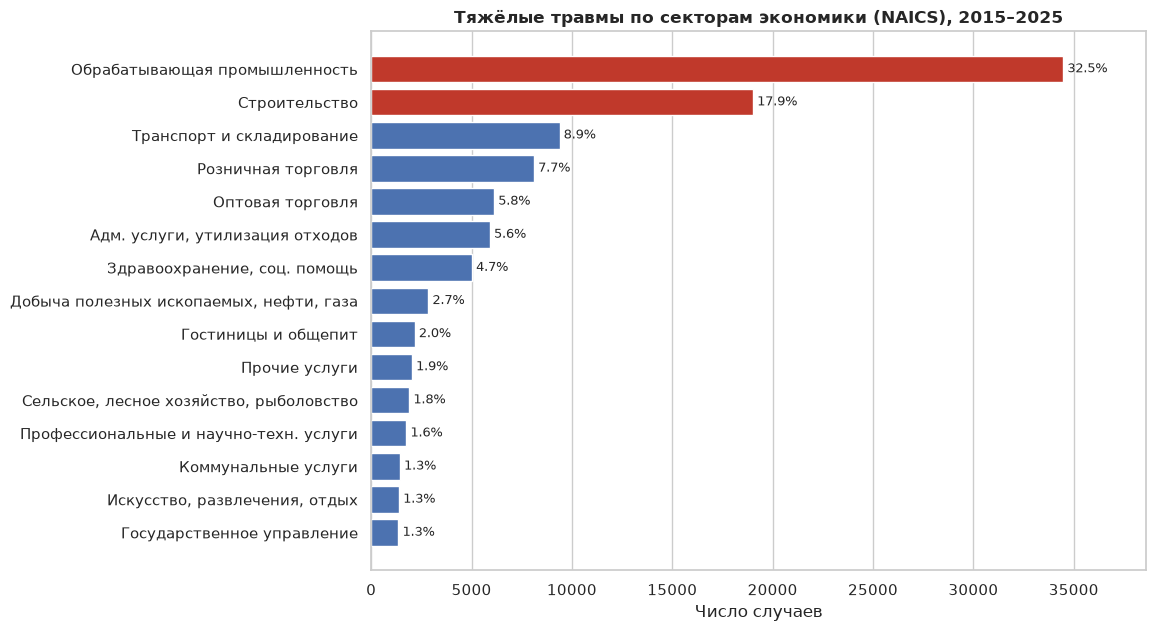

In [4]:
t = sec.head(15)
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    barh_ranked(ax, t["sector_ru"] if lang == "ru" else t["sector_en"], t["cases"],
                notes=[f"{p:.1f}%" for p in t["pct"]],
                color=[ACCENT if s in ("31-33", "23") else MAIN for s in t.index])
    ax.set_title(tr("Тяжёлые травмы по секторам экономики (NAICS), 2015–2025",
                    "Severe injuries by economic sector (NAICS), 2015–2025", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    finish(fig, "03_1_sectors", lang)

## 3.2. Топ-15 подсекторов (3 цифры NAICS)

In [5]:
sub = cases.loc[cases["naics_code"].str.len() >= 3, "subsector"].value_counts().rename("cases").to_frame()
sub["pct"] = 100 * sub["cases"] / N
sub["title"] = sub.index.map(lambda c: naics.get(c, "Unknown"))
sub["title_ru"] = [naics_ru(c, t) for c, t in zip(sub.index, sub["title"])]
sub["sector_ru"] = sub.index.map(lambda c: SECTORS.get(sector_code(c), ("",))[0])
sub.head(20).round(2).to_csv(TABLES_DIR / "03_2_top_subsectors.csv", encoding="utf-8-sig")
sub.head(20).round(2)

,cases,pct,title,title_ru,sector_ru
subsector,,,,,
238,11493,10.84,Specialty Trade Contractors,Специализированные строительные работы,Строительство
311,6430,6.07,Food Manufacturing,Пищевая промышленность,Обрабатывающая промышленность
332,5163,4.87,Fabricated Metal Product Manufacturing,Производство металлоизделий,Обрабатывающая промышленность
561,4382,4.13,Administrative and Support Services,Административные и вспомогательные услуги,"Адм. услуги, утилизация отходов"
237,4022,3.79,Heavy and Civil Engineering Construction,Инфраструктурное строительство,Строительство
236,3504,3.31,Construction of Buildings,Строительство зданий,Строительство
423,3409,3.22,"Merchant Wholesalers, Durable Goods",Оптовая торговля товарами длит. пользования,Оптовая торговля
336,2909,2.74,Transportation Equipment Manufacturing,Производство транспортного оборудования,Обрабатывающая промышленность
333,2670,2.52,Machinery Manufacturing,Машиностроение,Обрабатывающая промышленность


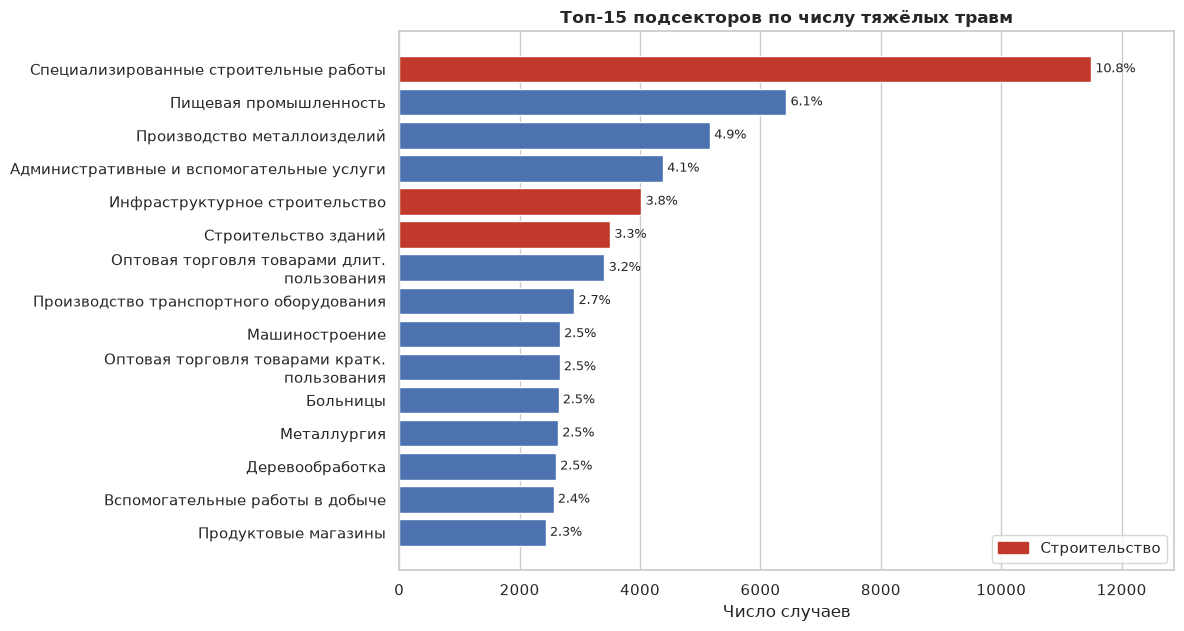

In [6]:
t = sub.head(15)
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    barh_ranked(ax, t["title_ru"] if lang == "ru" else t["title"], t["cases"],
                notes=[f"{p:.1f}%" for p in t["pct"]],
                color=[ACCENT if sector_code(c) == "23" else MAIN for c in t.index])
    ax.set_title(tr("Топ-15 подсекторов по числу тяжёлых травм", "Top 15 subsectors by severe injuries", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
              labels=[tr("Строительство", "Construction", lang)], loc="lower right")
    finish(fig, "03_2_top_subsectors", lang)

## 3.3. Топ-15 конкретных отраслей (6 цифр NAICS)

In [7]:
ind = cases.loc[~legacy & (cases["naics_code"].str.len() == 6), "naics_code"]
ind = ind.value_counts().rename("cases").to_frame()
ind["pct"] = 100 * ind["cases"] / N
ind["title"] = ind.index.map(naics)
ind["title_ru"] = [naics_ru(c, t) for c, t in zip(ind.index, ind["title"])]
ind["sector_ru"] = ind.index.map(lambda c: SECTORS.get(sector_code(c), ("",))[0])
ind.head(20).round(2).to_csv(TABLES_DIR / "03_3_top_industries.csv", encoding="utf-8-sig")
ind.head(20).round(2)

,cases,pct,title,title_ru,sector_ru
naics_code,,,,,
622110,2467,2.33,General Medical and Surgical Hospitals,Больницы общего профиля,"Здравоохранение, соц. помощь"
445110,2114,1.99,Supermarkets and Other Grocery Retailers (exce...,Супермаркеты и продуктовые магазины,Розничная торговля
238210,1969,1.86,Electrical Contractors and Other Wiring Instal...,Электромонтажные работы,Строительство
236220,1958,1.85,Commercial and Institutional Building Construc...,Строительство коммерческих зданий,Строительство
213112,1896,1.79,Support Activities for Oil and Gas Operations,Обслуживание нефтегазовых скважин,"Добыча полезных ископаемых, нефти, газа"
237310,1583,1.49,"Highway, Street, and Bridge Construction",Строительство дорог и мостов,Строительство
493110,1573,1.48,General Warehousing and Storage,Склады общего назначения,Транспорт и складирование
491110,1558,1.47,Postal Service,Почтовая служба,Транспорт и складирование
238160,1535,1.45,Roofing Contractors,Кровельные работы,Строительство


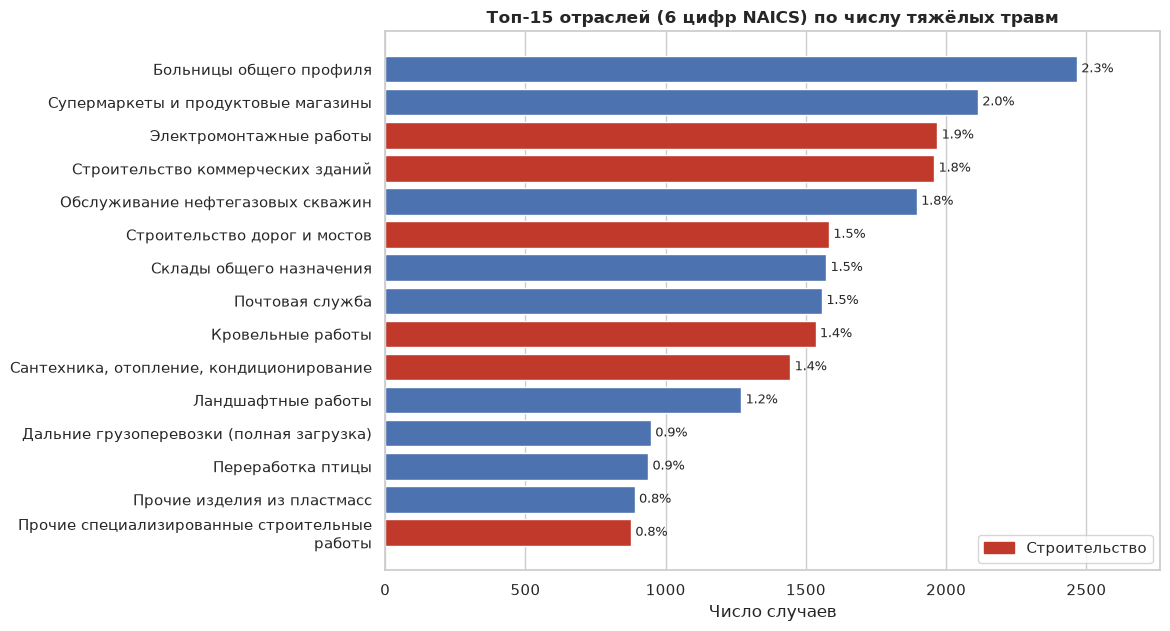

In [8]:
t = ind.head(15)
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    barh_ranked(ax, t["title_ru"] if lang == "ru" else t["title"], t["cases"],
                notes=[f"{p:.1f}%" for p in t["pct"]],
                color=[ACCENT if sector_code(c) == "23" else MAIN for c in t.index])
    ax.set_title(tr("Топ-15 отраслей (6 цифр NAICS) по числу тяжёлых травм",
                    "Top 15 industries (6-digit NAICS) by severe injuries", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
              labels=[tr("Строительство", "Construction", lang)], loc="lower right")
    finish(fig, "03_3_top_industries", lang)

## 3.4. Тяжесть последствий по секторам

Секторы с числом случаев ≥ 500. Доля ампутаций и госпитализаций с 95% ДИ Уилсона; связь сектора с ампутацией — χ² и V Крамера. Стандартизованные остатки показывают, где ампутаций больше ожидаемого.

In [9]:
big = sec[sec["cases"] >= 500].index
sub_cases = cases[cases["sector"].isin(big)]
rows = []
for s, g in sub_cases.groupby("sector"):
    a, a_lo, a_hi = share_ci(g["amputation"].sum(), len(g))
    h, h_lo, h_hi = share_ci(g["hospitalization"].sum(), len(g))
    rows.append({"sector": s, "sector_ru": SECTORS[s][0], "sector_en": SECTORS[s][1], "cases": len(g),
                 "pct_amputation": a, "amp_ci_low": a_lo, "amp_ci_high": a_hi,
                 "pct_hospitalized": h, "hosp_ci_low": h_lo, "hosp_ci_high": h_hi})
sev = pd.DataFrame(rows).sort_values("pct_amputation", ascending=False).reset_index(drop=True)
sev.round(2).to_csv(TABLES_DIR / "03_4_severity_by_sector.csv", index=False, encoding="utf-8-sig")

ct = pd.crosstab(sub_cases["sector"], sub_cases["amputation"])
chi2, p, dof, v, expected = cramers_v(ct)
print(f"Сектор × ампутация: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")
sev["amp_resid"] = sev["sector"].map(((ct - expected) / np.sqrt(expected))[True])
sev[["sector_ru", "cases", "pct_amputation", "pct_hospitalized", "amp_resid"]].round(1)

Сектор × ампутация: χ² = 9 766, df = 17, p = 0.00e+00, V Крамера = 0.304


,sector_ru,cases,pct_amputation,pct_hospitalized,amp_resid
0,Обрабатывающая промышленность,34472,44.7,67.0,66.0
1,"Добыча полезных ископаемых, нефти, газа",2843,29.7,78.2,3.3
2,"Сельское, лесное хозяйство, рыболовство",1895,26.5,82.1,0.0
3,Оптовая торговля,6121,26.2,81.8,-0.4
4,Прочие услуги,2028,24.1,83.2,-2.0
5,"Адм. услуги, утилизация отходов",5910,19.5,86.7,-10.3
6,Государственное управление,1354,18.6,86.1,-5.6
7,Гостиницы и общепит,2166,18.6,86.3,-7.1
8,Розничная торговля,8111,17.8,87.2,-15.1
9,Профессиональные и научно-техн. услуги,1748,17.5,88.7,-7.3


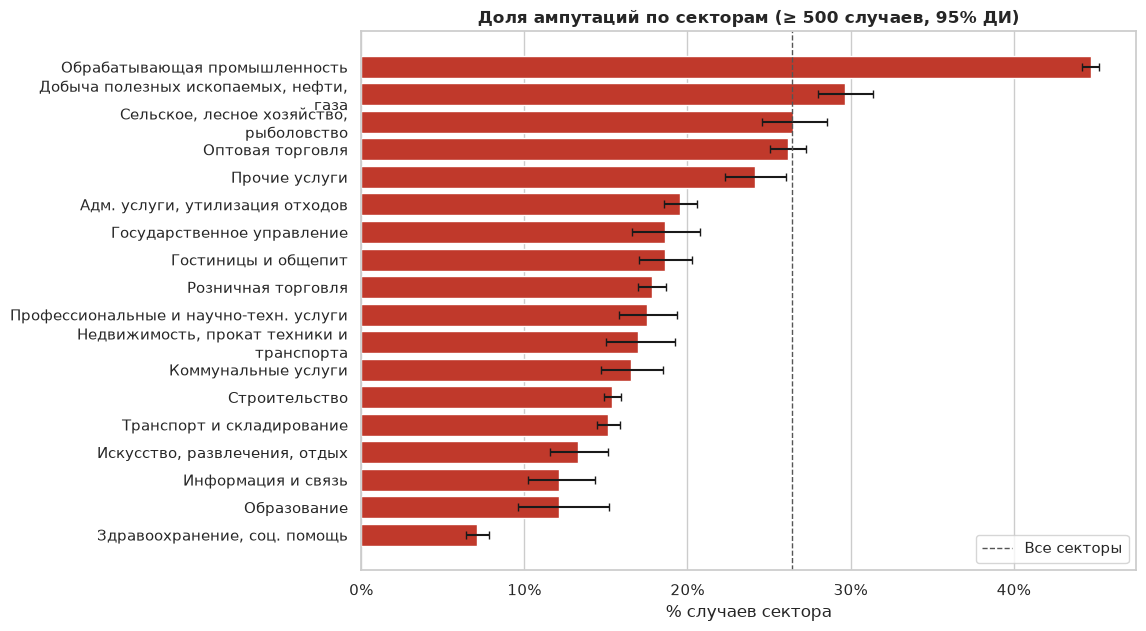

In [10]:
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    y = np.arange(len(sev))[::-1]
    ax.barh(y, sev["pct_amputation"], color=ACCENT,
            xerr=[sev["pct_amputation"] - sev["amp_ci_low"], sev["amp_ci_high"] - sev["pct_amputation"]], capsize=3)
    ax.axvline(100 * cases["amputation"].mean(), color="#555555", ls="--", lw=1,
               label=tr("Все секторы", "All sectors", lang))
    ax.set_yticks(y, [wrap(n, 38) for n in (sev["sector_ru"] if lang == "ru" else sev["sector_en"])])
    ax.set_title(tr("Доля ампутаций по секторам (≥ 500 случаев, 95% ДИ)",
                    "Share of amputations by sector (≥ 500 cases, 95% CI)", lang))
    ax.set_xlabel(tr("% случаев сектора", "% of sector cases", lang))
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    finish(fig, "03_4_amputation_by_sector", lang)

## 3.5. Секторы по годам

SQL 3.5 — топ-3 сектора каждого года (по всем годам это обрабатывающая промышленность, строительство, транспорт и склады). Здесь — доли крупнейших секторов по годам и линейный тренд доли.

In [11]:
top3 = (cases.groupby(["year", "sector"]).size().rename("cases").reset_index()
        .sort_values(["year", "cases"], ascending=[True, False]))
top3["pct_of_year"] = 100 * top3["cases"] / top3.groupby("year")["cases"].transform("sum")
top3["place"] = top3.groupby("year").cumcount() + 1
top3 = top3[top3["place"] <= 3].assign(sector_ru=lambda d: d["sector"].map(lambda s: SECTORS[s][0]))
top3.round(2).to_csv(TABLES_DIR / "03_5_top3_sectors_by_year.csv", index=False, encoding="utf-8-sig")

main = sec.index[:6].tolist()
share = pd.crosstab(cases["year"], cases["sector"], normalize="index")[main] * 100
share.round(2).to_csv(TABLES_DIR / "03_5_sector_share_by_year.csv", encoding="utf-8-sig")
for s in main:
    lr = stats.linregress(share.index, share[s])
    print(f"{SECTORS[s][0]:<34} наклон {lr.slope:+.2f} п.п. в год, R² = {lr.rvalue**2:.2f}, p = {lr.pvalue:.3f}")
share.set_axis([SECTORS[s][0] for s in main], axis=1).round(1)

Обрабатывающая промышленность      наклон -0.26 п.п. в год, R² = 0.46, p = 0.021
Строительство                      наклон +0.03 п.п. в год, R² = 0.02, p = 0.678
Транспорт и складирование          наклон +0.05 п.п. в год, R² = 0.17, p = 0.204
Розничная торговля                 наклон +0.11 п.п. в год, R² = 0.65, p = 0.003
Оптовая торговля                   наклон +0.08 п.п. в год, R² = 0.49, p = 0.016
Адм. услуги, утилизация отходов    наклон +0.02 п.п. в год, R² = 0.05, p = 0.510


,Обрабатывающая промышленность,Строительство,Транспорт и складирование,Розничная торговля,Оптовая торговля,"Адм. услуги, утилизация отходов"
year,,,,,,
2015,34.9,17.4,8.4,6.8,5.3,5.7
2016,33.4,18.5,8.9,7.5,5.4,5.0
2017,32.9,17.8,8.6,6.9,5.5,5.6
2018,32.4,17.6,8.5,7.4,5.5,5.8
2019,31.5,17.7,8.7,8.0,5.9,5.7
2020,31.8,19.4,9.1,8.0,5.8,5.8
2021,33.9,17.6,9.4,7.8,6.1,5.3
2022,32.4,16.6,9.5,7.9,6.5,5.6
2023,32.7,18.2,9.1,7.9,5.7,5.3


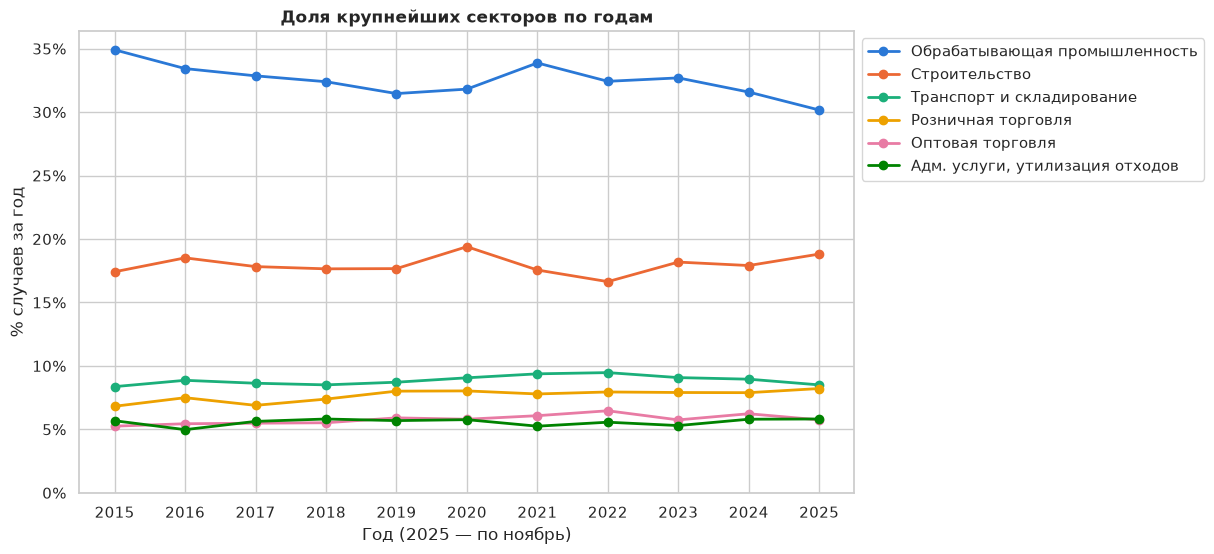

In [12]:
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(10, 6))
    for s, color in zip(main, SERIES):
        ax.plot(share.index, share[s], marker="o", color=color, lw=2, label=SECTORS[s][k])
    ax.set_title(tr("Доля крупнейших секторов по годам", "Share of the largest sectors by year", lang))
    ax.set_xlabel(tr("Год (2025 — по ноябрь)", "Year (2025 — through November)", lang))
    ax.set_ylabel(tr("% случаев за год", "% of cases in year", lang))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xticks(share.index)
    ax.set_ylim(0, None)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    finish(fig, "03_5_sector_share_by_year", lang)

## Выводы

1. **Три сектора дают 59% тяжёлых травм:** обрабатывающая промышленность (32,5%), строительство (18,0%), транспорт и складирование (8,9%). Среди подсекторов первое место у специализированных строительных работ (10,8% — кровельщики, электрики, сантехники, бетонщики), затем пищевая промышленность (6,1%) и производство металлоизделий (4,9%).
2. **Среди конкретных отраслей лидируют больницы общего профиля** (2,3%), супермаркеты (2,0%), электромонтаж и строительство коммерческих зданий (по 1,9%), обслуживание нефтегазовых скважин (1,8%). Это абсолютные числа, без учёта численности работников.
3. **Тяжесть сильно зависит от сектора** (χ² = 9 766, p < 0,001, V Крамера = 0,30). В обрабатывающей промышленности ампутацией заканчиваются 44,7% случаев — намного больше ожидаемого (станд. остаток +66); далее добыча (29,7%) и сельское хозяйство (26,5%). В строительстве (15,4%), транспорте (15,1%) и здравоохранении (7,1%) преобладают переломы от падений, а не ампутации.
4. **Структура по годам устойчива:** тройка лидеров одинакова во все годы. Доля обрабатывающей промышленности медленно снижается (−0,26 п.п. в год, p = 0,02), доли розничной и оптовой торговли растут (+0,11 и +0,08 п.п. в год).
5. Около 10% случаев имеют старые коды NAICS, которых нет в редакции 2022 года, поэтому надёжнее сравнение по сектору и подсектору (префиксу кода).